# Homework A — Unsupervised Learning
**Abiell Yuman Atsal · 23625313 · Group 3 · AE5004**

PCA and K = 3 clustering of the supplied Palmer penguin data. Run the cells from top to bottom. The notebook loads the exact CSV from GitHub, or asks for a local upload if access is unavailable. Figures and numerical results are saved in `outputs_A/`.

Species labels are held back until the external comparison. K = 3 is the selected finer partition; K = 2 has the highest silhouette.

## 1. Software and data

In [1]:
# Install the versions used in the report only when needed.
import sys, subprocess
from importlib.metadata import version, PackageNotFoundError
requirements = {'numpy': '2.5.5', 'pandas': '3.1.1', 'scipy': '1.18.1',
                'matplotlib': '3.11.2', 'scikit-learn': '1.9.1', 'statsmodels': '0.15.0'}
missing = []
for package, wanted in requirements.items():
    try:
        if version(package) != wanted:
            missing.append(f'{package}=={wanted}')
    except PackageNotFoundError:
        missing.append(f'{package}=={wanted}')
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print({package: version(package) for package in requirements})


{'numpy': '2.5.5', 'pandas': '3.1.1', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1', 'statsmodels': '0.15.0'}


In [2]:
from pathlib import Path
import json, hashlib
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
BASE = Path.cwd() / 'outputs_A ' .strip()
BASE.mkdir(exist_ok=True)
FIG = BASE / 'figures'
FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 140, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
def save(name):
    plt.tight_layout()
    plt.savefig(FIG / name, bbox_inches='tight')
    plt.show()
    plt.close()
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from scipy.optimize import linear_sum_assignment
def km(k):
    return KMeans(n_clusters=k, n_init=50, random_state=42)


In [3]:
filename = 'penguins_raw.csv'
expected_sha256 = 'd199d858c85bb009f37f651a28e73fa2977f8dc7a485b3884187d3fc24949c18'
candidates = [Path('data') / filename, Path(filename)]
DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    # Immutable repository revision: uses exactly the supplied data vintage.
    url = 'https://raw.githubusercontent.com/abiellyuman/Assignment-Data-Analytics/be8d6e3f2a0f0fa1e452a9bf65cf58682a38f899/' + filename
    try:
        with urlopen(url, timeout=30) as response:
            content = response.read()
    except Exception:
        # For a private repository or unavailable connection, upload your CSV.
        try:
            from google.colab import files
        except ImportError as exc:
            raise RuntimeError('Place ' + filename + ' beside this notebook or in data/.') from exc
        print('Select the supplied file: ' + filename)
        uploaded = files.upload()
        if filename not in uploaded:
            raise ValueError('Expected ' + filename)
        content = uploaded[filename]
    DATA_PATH = Path(filename)
    DATA_PATH.write_bytes(content)
actual = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
if actual != expected_sha256:
    raise ValueError('The CSV differs from the version used in the report. Use the supplied original file.')
print('Dataset:', DATA_PATH, '\nSHA256:', actual)


Dataset: data/penguins_raw.csv 
SHA256: d199d858c85bb009f37f651a28e73fa2977f8dc7a485b3884187d3fc24949c18


## 2. Complete cases, standardization and PCA
Only the four numeric features determine which observations are retained. PCA loadings below are eigenvector coefficients.

In [4]:
p=pd.read_csv(DATA_PATH)
cols=['Culmen Length (mm)','Culmen Depth (mm)','Flipper Length (mm)','Body Mass (g)']
v=p.dropna(subset=cols).copy(); z=StandardScaler().fit_transform(v[cols]); pc=PCA().fit(z); u=pc.transform(z)[:,:2]

print(f'Original rows: {len(p)}; complete rows: {len(v)}')
assert len(v) == 342
display(pd.DataFrame({'Component':['PC1','PC2','PC3','PC4'], 'Eigenvalue':pc.explained_variance_, 'Variance explained':pc.explained_variance_ratio_, 'Cumulative':pc.explained_variance_ratio_.cumsum()}))
display(pd.DataFrame(pc.components_[:2].T, index=cols, columns=['PC1 loading','PC2 loading']))


Original rows: 344; complete rows: 342


,Component,Eigenvalue,Variance explained,Cumulative
0,PC1,2.761831,0.688439,0.688439
1,PC2,0.774782,0.193129,0.881568
2,PC3,0.366307,0.091309,0.972877
3,PC4,0.108810,0.027123,1.000000


,PC1 loading,PC2 loading
Culmen Length (mm),0.455250,0.597031
Culmen Depth (mm),-0.400335,0.797767
Flipper Length (mm),0.576013,0.002282
Body Mass (g),0.548350,0.084363


## 3. Elbow and silhouette
The internal scan excludes species. The silhouette favors K = 2; K = 3 retains a finer partition near the bend of the inertia curve.

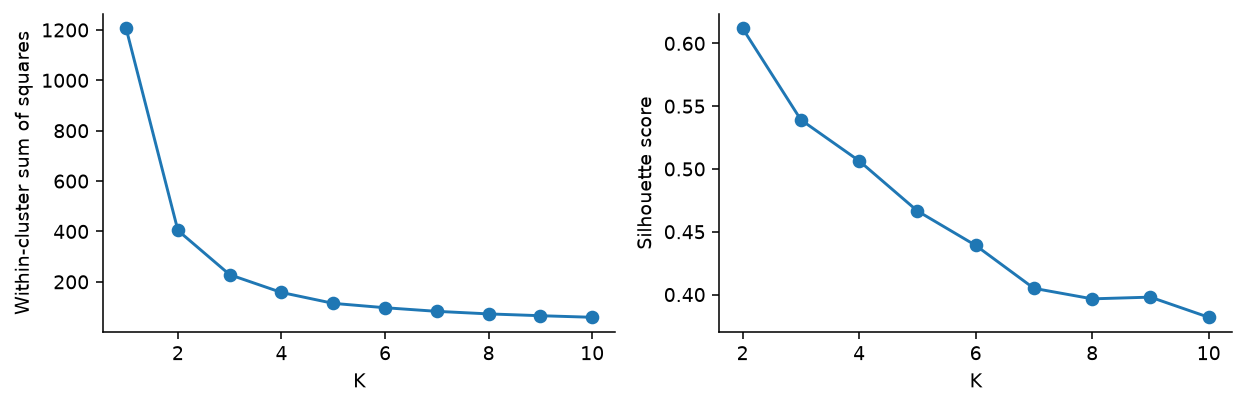

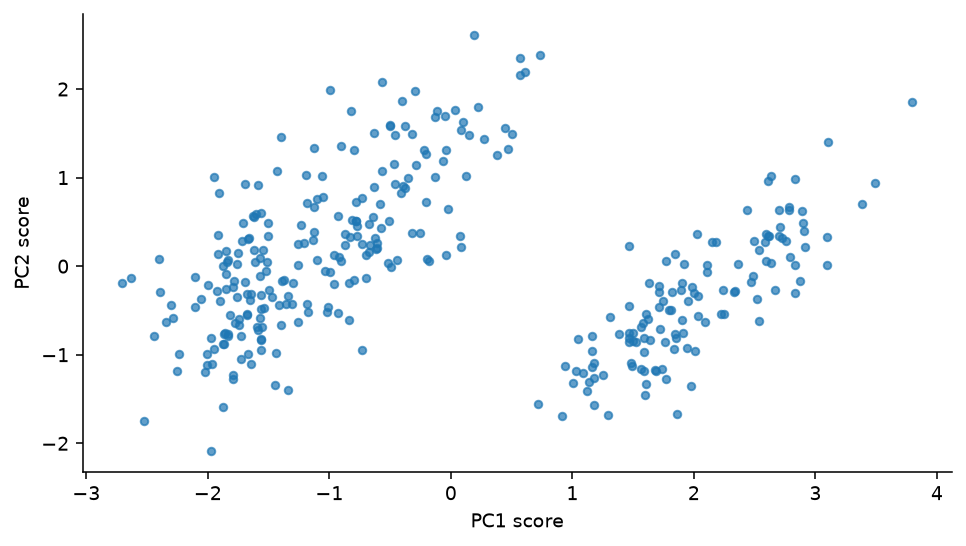

,K,Inertia,Silhouette
0,2,403.954894,0.611872
1,3,228.330105,0.539103
2,4,157.726083,0.506433
3,5,114.506877,0.466545
4,6,97.190537,0.439145
5,7,82.809130,0.404959
6,8,72.652175,0.396588
7,9,65.479329,0.397950
8,10,59.241509,0.381912


In [5]:
ks=list(range(2,11)); inertia=[]; sil=[]
for k in ks:
 m=km(k).fit(u); inertia.append(m.inertia_); sil.append(silhouette_score(u,m.labels_))
m1=km(1).fit(u)
fig,ax=plt.subplots(1,2,figsize=(9,3)); ax[0].plot([1]+ks,[m1.inertia_]+inertia,'o-'); ax[0].set(xlabel='K',ylabel='Within-cluster sum of squares'); ax[1].plot(ks,sil,'o-'); ax[1].set(xlabel='K',ylabel='Silhouette score'); save('a_k.png')
fig,ax=plt.subplots(figsize=(7,4)); ax.scatter(u[:,0],u[:,1],s=15,alpha=.7); ax.set(xlabel='PC1 score',ylabel='PC2 score'); save('a_pca.png')

display(pd.DataFrame({'K':ks, 'Inertia':inertia, 'Silhouette':sil}))


## 4. Fit K = 3 clusters
Fit K-means and Ward on PC1–PC2 and on all four standardized features before revealing species.

In [6]:
models={}; labels={}
# Species first accessed only after the unsupervised K scan and illustrative K=3 models.
for space,a in [('2D',u),('4D',z)]:
 for method in ['K-means','Ward']:
  model=km(3) if method=='K-means' else AgglomerativeClustering(n_clusters=3,linkage='ward')
  lab=model.fit_predict(a); labels[space+' '+method]=lab
  models[space+' '+method]={'silhouette':float(silhouette_score(a,lab))}


## 5. Reveal species and compare the partitions
Colors are aligned to species using optimal one-to-one matching only after fitting. Black crosses mark disagreements. Four-feature assignments are displayed on the common PC plane, but were fitted in four dimensions.

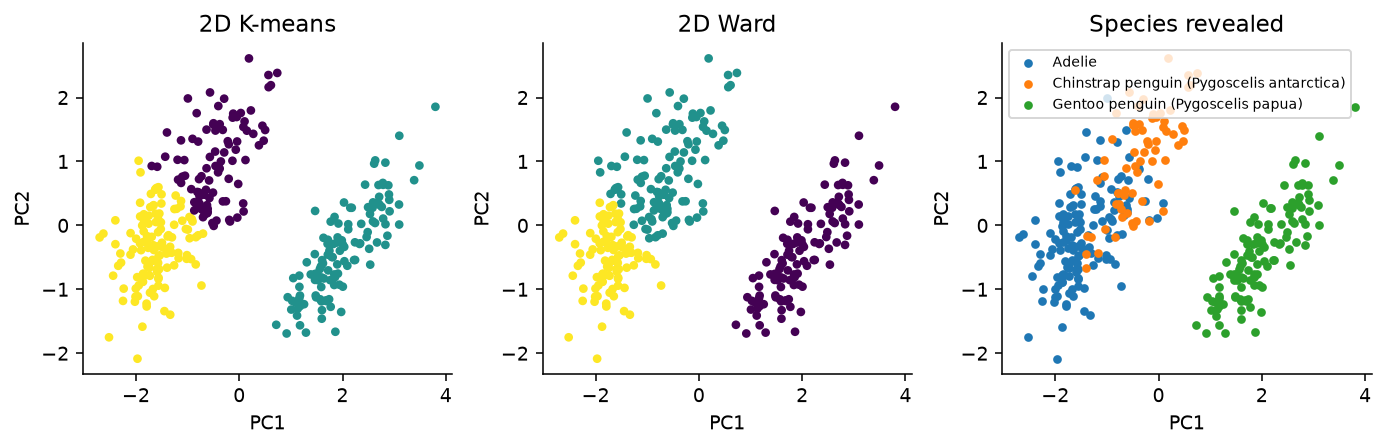

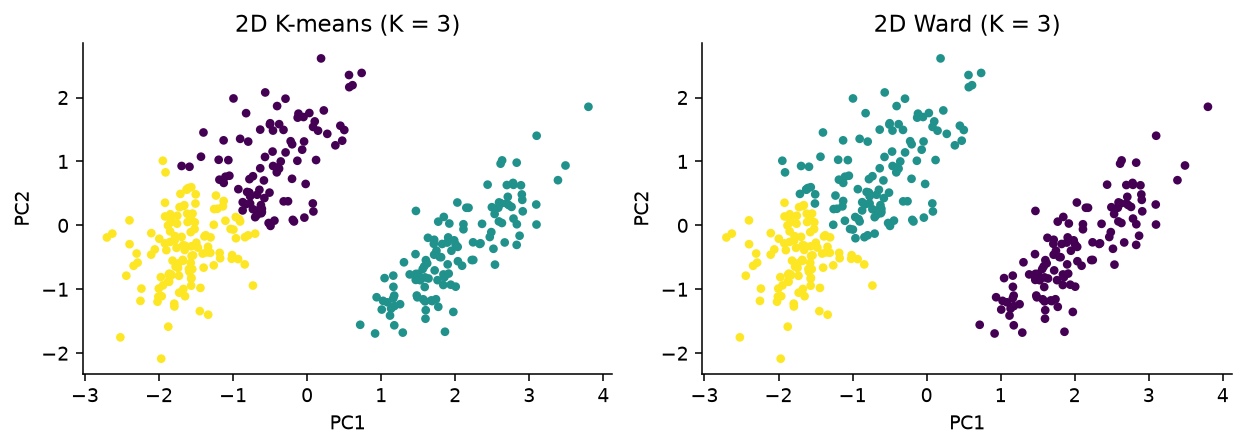

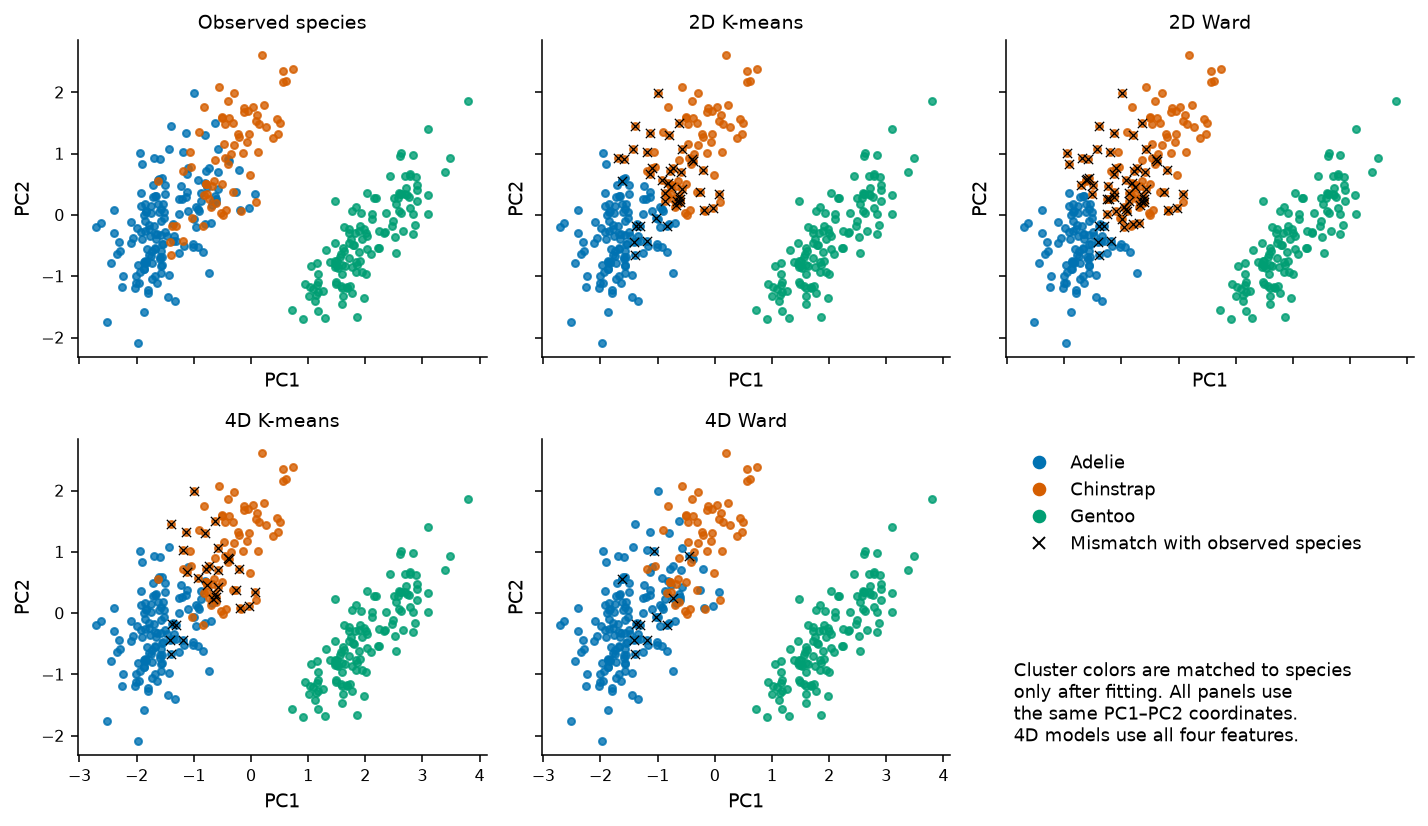

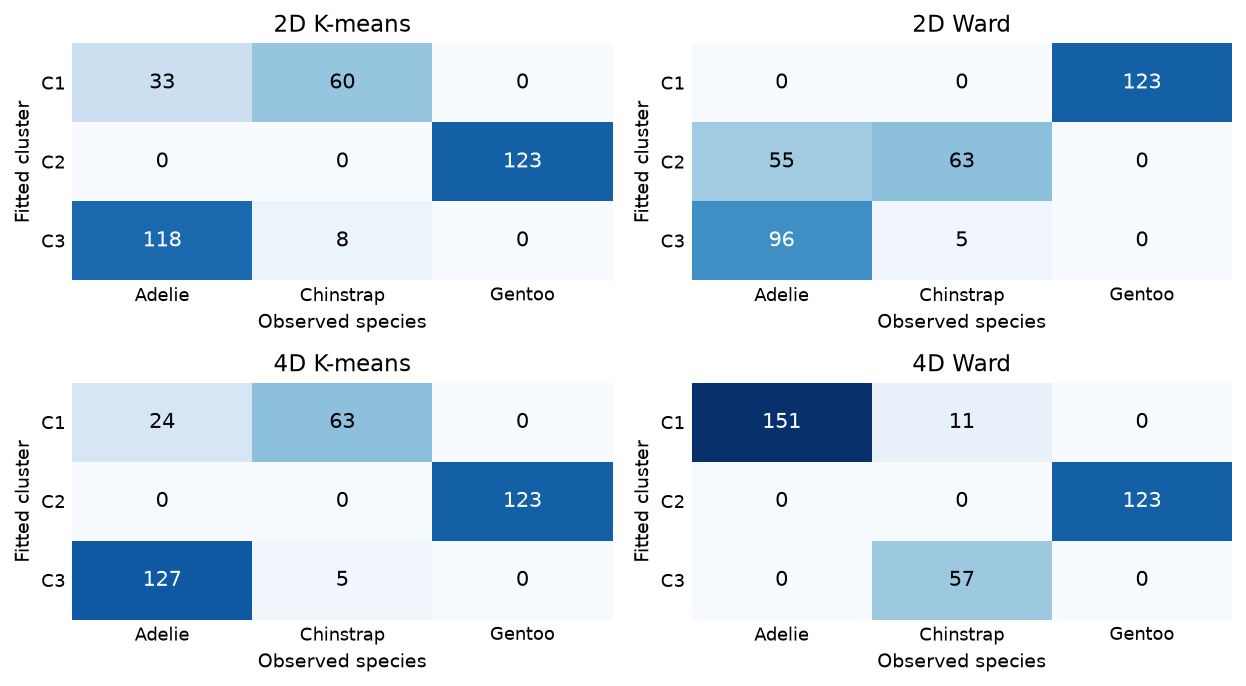

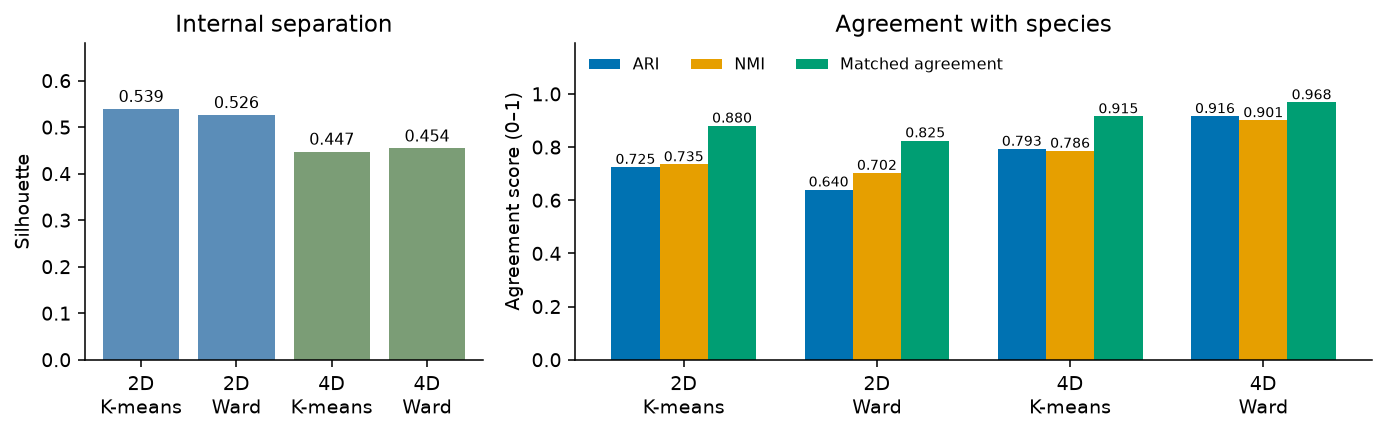

In [7]:
y=v.Species.astype('category').cat.codes.to_numpy(); species=list(v.Species.astype('category').cat.categories)
for key,lab in labels.items():
 tab=pd.crosstab(pd.Series(lab,name='Cluster'),pd.Series(y,name='Species')).reindex(index=range(len(np.unique(lab))),columns=range(3),fill_value=0).to_numpy()
 rr,cc=linear_sum_assignment(-tab)
 models[key].update(ari=float(adjusted_rand_score(y,lab)),nmi=float(normalized_mutual_info_score(y,lab)),mapped_accuracy=float(tab[rr,cc].sum()/len(y)),table=tab.tolist())
fig,ax=plt.subplots(1,3,figsize=(10,3.3))
for a,key in zip(ax[:2],['2D K-means','2D Ward']):
 a.scatter(u[:,0],u[:,1],c=labels[key],cmap='viridis',s=12); a.set(title=key,xlabel='PC1',ylabel='PC2')
for i,name in enumerate(species): ax[2].scatter(u[y==i,0],u[y==i,1],s=12,label=name.split(' Penguin')[0])
ax[2].set(title='Species revealed',xlabel='PC1',ylabel='PC2'); ax[2].legend(fontsize=7); save('a_clusters.png')
fig,ax=plt.subplots(1,2,figsize=(9,3.3))
for a,key in zip(ax,['2D K-means','2D Ward']):
 a.scatter(u[:,0],u[:,1],c=labels[key],cmap='viridis',s=12); a.set(title=key+' (K = 3)',xlabel='PC1',ylabel='PC2')
save('a_k3.png')
# Reveal labels after fitting; align arbitrary cluster colors using optimal matching.
from matplotlib.lines import Line2D
palette=['#0072B2','#D55E00','#009E73'];names=['Adelie','Chinstrap','Gentoo']
fig,axes=plt.subplots(2,3,figsize=(10.5,6),sharex=True,sharey=True)
plots=[('Observed species',y)]; mismatches={}
for key,lab in labels.items():
 tab=np.array(models[key]['table']);rr,cc=linear_sum_assignment(-tab)
 mapping=dict(zip(rr,cc));matched=np.array([mapping[int(k)] for k in lab])
 mismatches[key]=int((matched!=y).sum());plots.append((key,matched))
for ax,(title,groups) in zip(axes.flat,plots):
 for k in range(3):
  mask=groups==k;ax.scatter(u[mask,0],u[mask,1],s=13,color=palette[k],alpha=.8)
 if title in mismatches:
  bad=groups!=y;ax.scatter(u[bad,0],u[bad,1],s=23,marker='x',color='black',linewidths=.65)
 ax.set(title=title,xlabel='PC1',ylabel='PC2');ax.tick_params(labelsize=8);ax.title.set_fontsize(10)
axes.flat[-1].set_axis_off()
handles=[Line2D([0],[0],marker='o',linestyle='',color=palette[i],label=names[i]) for i in range(3)]
handles.append(Line2D([0],[0],marker='x',linestyle='',color='black',label='Mismatch with observed species'))
axes.flat[-1].legend(handles=handles,loc='upper left',frameon=False,fontsize=9)
axes.flat[-1].text(.02,.30,'Cluster colors are matched to species\nonly after fitting. All panels use\nthe same PC1–PC2 coordinates.\n4D models use all four features.',transform=axes.flat[-1].transAxes,fontsize=9,va='top')
save('a_reveal.png')
fig,axes=plt.subplots(2,2,figsize=(9,5))
for ax,(key,m) in zip(axes.flat,models.items()):
 tab=np.array(m['table']);ax.imshow(tab,cmap='Blues',vmin=0,vmax=151,aspect='auto')
 ax.set(xticks=range(3),xticklabels=names,yticks=range(3),yticklabels=['C1','C2','C3'],title=key,xlabel='Observed species',ylabel='Fitted cluster')
 ax.tick_params(axis='both',length=0,labelsize=9)
 for (i,j),value in np.ndenumerate(tab):ax.text(j,i,str(value),ha='center',va='center',color='white' if value>75 else 'black',fontsize=11)
 for spine in ax.spines.values():spine.set_visible(False)
save('a_counts.png')
fig,axes=plt.subplots(1,2,figsize=(10,3.2),gridspec_kw={'width_ratios':[1,2]})
keys=list(models);xx=np.arange(4);short=['2D\nK-means','2D\nWard','4D\nK-means','4D\nWard']
bars=axes[0].bar(xx,[models[k]['silhouette'] for k in keys],color=['#5B8DB8','#5B8DB8','#7B9D76','#7B9D76'])
axes[0].set(xticks=xx,xticklabels=short,ylim=(0,.68),ylabel='Silhouette',title='Internal separation')
for b in bars:axes[0].text(b.get_x()+b.get_width()/2,b.get_height()+.015,f'{b.get_height():.3f}',ha='center',fontsize=8)
for j,(field,name,color) in enumerate([('ari','ARI','#0072B2'),('nmi','NMI','#E69F00'),('mapped_accuracy','Matched agreement','#009E73')]):
 bars=axes[1].bar(xx+(j-1)*.25,[models[k][field] for k in keys],width=.25,label=name,color=color)
 for b in bars:axes[1].text(b.get_x()+b.get_width()/2,b.get_height()+.012,f'{b.get_height():.3f}',ha='center',fontsize=7)
axes[1].set(xticks=xx,xticklabels=short,ylim=(0,1.19),ylabel='Agreement score (0–1)',title='Agreement with species')
axes[1].legend(fontsize=8,ncol=3,loc='upper left',frameon=False)
save('a_metrics.png')



In [8]:
metric_table = pd.DataFrame({key:{name:value for name,value in m.items() if name != 'table'} for key,m in models.items()}).T
display(metric_table)
counts = pd.concat({key:pd.DataFrame(m['table'], index=['C1','C2','C3'], columns=['Adelie','Chinstrap','Gentoo']) for key,m in models.items()}, names=['Method','Cluster'])
display(counts)
metric_table.to_csv(BASE / 'clustering_metrics.csv')
counts.to_csv(BASE / 'cluster_species_counts.csv')
summary = {'n_total':len(p), 'n_complete':len(v), 'selected_k':3,
           'variance':pc.explained_variance_ratio_.tolist(), 'models':models}
(BASE / 'results_A.json').write_text(json.dumps(summary, indent=2))
print('Results saved to', BASE)


,silhouette,ari,nmi,mapped_accuracy
2D K-means,0.539103,0.724944,0.734624,0.880117
2D Ward,0.525979,0.639695,0.702413,0.824561
4D K-means,0.447219,0.792837,0.785503,0.915205
4D Ward,0.454095,0.915940,0.900710,0.967836


Adelie  Chinstrap  Gentoo
Method     Cluster                           
2D K-means C1           33         60       0
           C2            0          0     123
           C3          118          8       0
2D Ward    C1            0          0     123
           C2           55         63       0
           C3           96          5       0
4D K-means C1           24         63       0
           C2            0          0     123
           C3          127          5       0
4D Ward    C1          151         11       0
           C2            0          0     123
           C3            0         57       0

Results saved to /workspace/revised_submission/notebook_validation/A/outputs_A


## Conclusion
With K = 3, both methods separate Gentoo well. Retaining all four features improves agreement with species, especially for Ward clustering (ARI 0.916; matched agreement 96.78%). The remaining errors are 11 Chinstrap placed in the Adelie-matched cluster. PCA preserves most variance in two components, but its omitted components still help separate Adelie from Chinstrap.

## Sources
Palmer penguin data: Horst, Hill and Gorman (2020), doi:10.5281/zenodo.3960218. The supplied CSV is used unchanged. Cluster IDs are arbitrary, and matched agreement is in-sample agreement rather than predictive accuracy.